In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/customer_transactions.csv')

df.head(10)

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_qty,tot_sales,clean_prod_name,net_weight,brand,lifestage,premium_customer
0,2018-10-17,1,1000,1,5,2,6.0,natural chip compny seasalt 175 g,175,Natural Chip Company,YOUNG SINGLES/COUPLES,Premium
1,2019-05-14,1,1307,348,66,3,6.3,ccs nacho cheese 175 g,175,CCs,MIDAGE SINGLES/COUPLES,Budget
2,2019-05-20,1,1343,383,61,2,2.9,smiths crinkle cut chips chicken 170 g,170,Smith's,MIDAGE SINGLES/COUPLES,Budget
3,2018-08-17,2,2373,974,69,5,15.0,smiths chip thinly s cream onion 175 g,175,Smith's,MIDAGE SINGLES/COUPLES,Budget
4,2018-08-18,2,2426,1038,108,3,13.8,kettle tortilla chpshny jlpno chili 150 g,150,Kettle,MIDAGE SINGLES/COUPLES,Budget
5,2019-05-16,4,4149,3333,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget
6,2019-05-16,4,4196,3539,24,1,3.6,grain waves sweet chilli 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
7,2018-08-20,5,5026,4525,42,1,3.9,doritos corn chip mexican jalapeno 150 g,150,Doritos,MIDAGE SINGLES/COUPLES,Budget
8,2018-08-18,7,7150,6900,52,2,7.2,grain waves sour cream chives 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
9,2019-05-17,7,7215,7176,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget


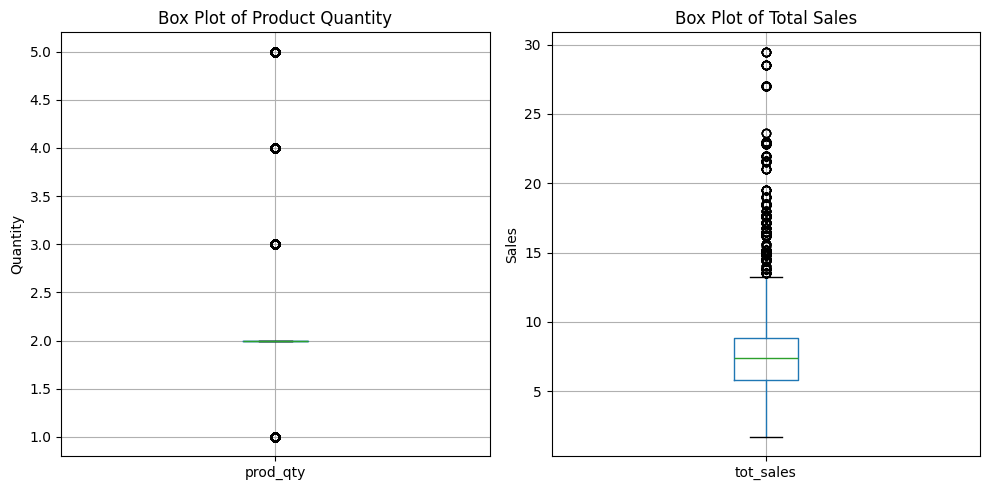

In [2]:
# get a grasp of the distribution of prod_qty and tot_sales using box plots

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

df.boxplot(column="prod_qty", ax=axes[0])
axes[0].set_title("Box Plot of Product Quantity")
axes[0].set_ylabel("Quantity")

df.boxplot(column="tot_sales", ax=axes[1])
axes[1].set_title("Box Plot of Total Sales")
axes[1].set_ylabel("Sales")

plt.tight_layout()
plt.show()

**Product Quantity**
- the usual customer would purchase 2 units
    *quartiles and median appear to converge at 2 units*
- The outliers at 1, 3, 4, and 5 units are not necessarily unusual purchasing behaviors. 
    *They simply fall outside the very narrow interquartile range*

**Total Sales**
- Most txns are concentrated between 5.8 and 8.8
- Median of approx 7.4
- numerous upper-end outliers, stretching to nearly 30
    *The longer upper tail suggests that a relatively small number of transactions generate considerably higher sales than typical purchases.*

In [3]:
import pandas as pd


def build_sales_pivot(df, row_col="premium_customer", col_col="lifestage",
                      value_col="tot_sales", as_percent=True):
    """Plain pivot of value_col by row_col x col_col, with Grand Totals.

    as_percent=True  -> each cell is its share of overall sales (%)
    as_percent=False -> raw summed sales
    Returns (numeric_pivot, formatted_pivot).
    """
    pivot = df.pivot_table(index=row_col, columns=col_col, values=value_col,
                           aggfunc="sum", fill_value=0,
                           margins=True, margins_name="Grand Total")

    if as_percent:
        pivot = pivot / pivot.loc["Grand Total", "Grand Total"] * 100

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the original pivot
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    fmt = (lambda v: f"{v:.2f}%") if as_percent else (lambda v: f"{v:,.2f}")
    formatted = pivot.apply(lambda col: col.map(fmt))
    return pivot, formatted



pivot, pivot_fmt = build_sales_pivot(df)
display(pivot_fmt)    

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,1.84%,1.14%,8.68%,7.08%,5.87%,7.18%,3.16%,34.96%
Mainstream,4.70%,0.89%,5.34%,6.90%,8.05%,4.78%,8.19%,38.84%
Premium,3.02%,0.60%,4.17%,6.85%,5.06%,4.35%,2.16%,26.20%
Grand Total,9.56%,2.63%,18.19%,20.83%,18.98%,16.31%,13.51%,100.00%


- Older Singles/Couples account for 20.83% of sales, the highest across all life stages on top of being the most consistent across three pricing levels [avg: 6.94%]
- Both budget Older [8.68%] and Young Families [7.18%] perform better than the Mainstream and Premium counterparts from their life stage 
- The older cohort [retirees], [older_families], and [older_s/c] account for [58%] of all sales, currently the highest average [19.33%perLifestage].
- Mainstream Young S/C account for the second highest individual cohort sales at [8.19%]

*premium members account for 26.20% of sales, the lowest across three membership pricing tiers*

- does headcount influence sales?
- do the outliers [sales_boxplot] produce disproportionate sales?

In [4]:

def build_customer_pivot(df, row_col="premium_customer", col_col="lifestage",
                         customer_col="lylty_card_nbr", as_percent=True):
    #Plain pivot of unique customers by row_col x col_col, with Grand Totals.
    
    # nunique inside margins also gives true unique counts for the totals
    pivot = df.pivot_table(index=row_col, columns=col_col, values=customer_col,
                           aggfunc="nunique", fill_value=0,
                           margins=True, margins_name="Grand Total")

    if as_percent:
        pivot = pivot / pivot.loc["Grand Total", "Grand Total"] * 100

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the original pivot
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    fmt = (lambda v: f"{v:.2f}%") if as_percent else (lambda v: f"{int(v):,}")
    formatted = pivot.apply(lambda col: col.map(fmt))
    return pivot, formatted


pivot, pivot_fmt = build_customer_pivot(df)
display(pivot_fmt)                   

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,2.07%,1.53%,6.47%,6.80%,6.15%,5.55%,5.10%,33.66%
Mainstream,4.63%,1.16%,3.91%,6.82%,8.91%,3.77%,11.11%,40.31%
Premium,3.33%,0.81%,3.13%,6.57%,5.35%,3.37%,3.48%,26.03%
Grand Total,10.02%,3.50%,13.51%,20.19%,20.41%,12.69%,19.69%,100.00%


*numbers are similar to the total sales pivot chart, let's compare it*

In [5]:
def build_sales_vs_customers(df, group_col="lifestage", value_col="tot_sales",
                             customer_col="lylty_card_nbr"):
    """Plain table by group_col: sales %, customers %, and the % differential.

    d_Sales      = share of total sales (%)
    d_Customers  = share of total unique customers (%)
    Difference   = d_Sales - d_Customers (percentage points)
    A Grand Total row tallies each column.
    Returns (numeric_table, formatted_table).
    """
    sales = df.groupby(group_col)[value_col].sum()
    customers = df.groupby(group_col)[customer_col].nunique()

    table = pd.DataFrame({
        "d_Sales": sales / sales.sum() * 100,
        "d_Customers": customers / customers.sum() * 100,
    })
    table["Difference"] = table["d_Sales"] - table["d_Customers"]

    # Display labels, then tally the Grand Total row
    table.index = [str(i).upper() for i in table.index]
    table.index.name = group_col.capitalize()
    table.loc["Grand Total"] = table.sum()

    formatted = table.apply(lambda col: col.map(lambda v: f"{round(v, 2) + 0.0:.2f}%"))
    return table, formatted



table, table_fmt = build_sales_vs_customers(df)
display(table_fmt)                 

,d_Sales,d_Customers,Difference
Lifestage,,,
MIDAGE SINGLES/COUPLES,9.56%,10.02%,-0.46%
NEW FAMILIES,2.63%,3.50%,-0.87%
OLDER FAMILIES,18.19%,13.51%,4.68%
OLDER SINGLES/COUPLES,20.83%,20.19%,0.64%
RETIREES,18.98%,20.41%,-1.43%
YOUNG FAMILIES,16.31%,12.69%,3.62%
YOUNG SINGLES/COUPLES,13.51%,19.69%,-6.18%
Grand Total,100.00%,100.00%,0.00%


*in general, sales is almost 1:1 with population*
    - consumers spend a similar amount on average

**Older Families** and **Young Families** produce slightly greater sales compared to their headcount
    - this makes sense, they are purchasing a family's worth of chips

**Young Singles/Couples** produce sales that are -6.18% less than their headcount
    - sales is only 68.6% of their headcount, low when compared to counterparts with <1% differentials

In [6]:
# average spend per customer by lifestage and membership tier

def build_avg_spend_pivot(df, row_col="premium_customer", col_col="lifestage",
                          value_col="tot_sales", customer_col="lylty_card_nbr"):
    
    """Plain pivot of average spend per customer by row_col x col_col."""
    
    total_sales = df.pivot_table(index=row_col, columns=col_col, values=value_col,
                                 aggfunc="sum", fill_value=0,
                                 margins=True, margins_name="Grand Total")
    customers = df.pivot_table(index=row_col, columns=col_col, values=customer_col,
                               aggfunc="nunique", fill_value=0,
                               margins=True, margins_name="Grand Total")

    pivot = total_sales / customers  # empty segments become NaN

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the other pivots
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    formatted = pivot.apply(lambda col: col.map(lambda v: "-" if pd.isna(v) else f"{v:,.2f}"))
    return pivot, formatted


pivot, pivot_fmt = build_avg_spend_pivot(df)
display(pivot_fmt)

,MIDAGE SINGLES/COUPLES,NEW FAMILIES,OLDER FAMILIES,OLDER SINGLES/COUPLES,RETIREES,YOUNG FAMILIES,YOUNG SINGLES/COUPLES,Grand Total
AFFLUENCE,,,,,,,,
Budget,22.55,18.91,33.89,26.30,24.13,32.69,15.64,26.24
Mainstream,25.64,19.25,34.53,25.56,22.80,32.02,18.62,24.34
Premium,22.92,18.66,33.60,26.32,23.90,32.61,15.71,25.42
Grand Total,24.10,18.96,34.01,26.06,23.49,32.47,17.33,25.26


*spending amount is similar across affluence levels, with the difference hovering only at around 1-2%*
 - **lifestage is a better indicator of spending average**

NameError: name 'lifestage_spend' is not defined

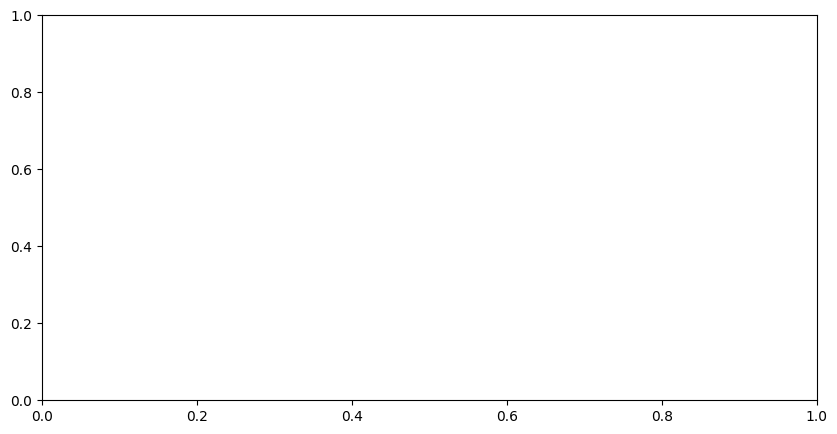

In [7]:
# look at the average spend by lifestage across all customers

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(lifestage_spend.index, lifestage_spend.values, color="steelblue")
ax.invert_yaxis()  # Highest average spend at the top

ax.set_title("Average Spend by Lifestage")
ax.set_xlabel("Average Spend")
ax.set_ylabel("Lifestage")

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)

ax.margins(x=0.1)
plt.tight_layout()
plt.show()

*On average, families spend more per transaction compared to other lifestages*

*Retirees, as well as Older & Midage S/C sit at the middle in terms of avg spend*

*Younger, and non-family segments spend the lowest on average*

 - these points just make sense, given each lifestage's practical priorities

 *from these generalized data, let's dive deeper on the cohorts spending habits*

In [ ]:
import pandas as pd


def build_avg_txn_pivot(df, row_col="premium_customer", col_col="lifestage",
                        txn_col="txn_id", customer_col="lylty_card_nbr",
                        unique_txns=True):
    """Plain pivot of average transactions per customer by row_col x col_col.

    Average transactions per customer = number of transactions / unique customers.
    unique_txns=True  -> transactions = unique txn_id values
    unique_txns=False -> transactions = number of rows (use this if txn_id is
                         not unique across stores or repeats for one purchase)
    Grand Totals come from the underlying totals (not an average of averages).
    Returns (numeric_pivot, formatted_pivot).
    """
    txn_agg = "nunique" if unique_txns else "count"
    txns = df.pivot_table(index=row_col, columns=col_col, values=txn_col,
                          aggfunc=txn_agg, fill_value=0,
                          margins=True, margins_name="Grand Total")
    customers = df.pivot_table(index=row_col, columns=col_col, values=customer_col,
                               aggfunc="nunique", fill_value=0,
                               margins=True, margins_name="Grand Total")

    pivot = txns / customers  # empty segments become NaN

    # Logical row order, Grand Total last
    order = [r for r in ["Budget", "Mainstream", "Premium"] if r in pivot.index]
    others = [r for r in pivot.index if r not in order + ["Grand Total"]]
    pivot = pivot.loc[order + others + ["Grand Total"]]

    # Display labels matching the other pivots
    pivot.index.name = "AFFLUENCE" if row_col == "premium_customer" else row_col.upper()
    pivot.columns.name = col_col.upper()
    pivot.columns = [str(c).upper() if c != "Grand Total" else c for c in pivot.columns]

    formatted = pivot.apply(lambda col: col.map(lambda v: "-" if pd.isna(v) else f"{v:,.2f}"))
    return pivot, formatted


pivot, pivot_fmt = build_avg_txn_pivot(df)
display(pivot_fmt)

NameError: name 'df' is not defined